1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from imblearn.over_sampling import SMOTE

2. Load Dataset

In [ ]:
# Load and clean data
df = pd.read_csv('pd_speech_features.csv')
df.drop(columns=["id"], inplace=True, errors='ignore')

# Drop rows where target class is NaN
df = df.dropna(subset=['class'])

# Print diagnostics
print("Dataset shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Target class distribution:\n", df['class'].value_counts())

Dataset shape: (756, 754)
Missing values:
 gender                       0
PPE                          0
DFA                          0
RPDE                         0
numPulses                    0
                            ..
tqwt_kurtosisValue_dec_33    0
tqwt_kurtosisValue_dec_34    0
tqwt_kurtosisValue_dec_35    0
tqwt_kurtosisValue_dec_36    0
class                        0
Length: 754, dtype: int64
Target class distribution:
 class
1    564
0    192
Name: count, dtype: int64


3. Initial Class Distribution Visualization

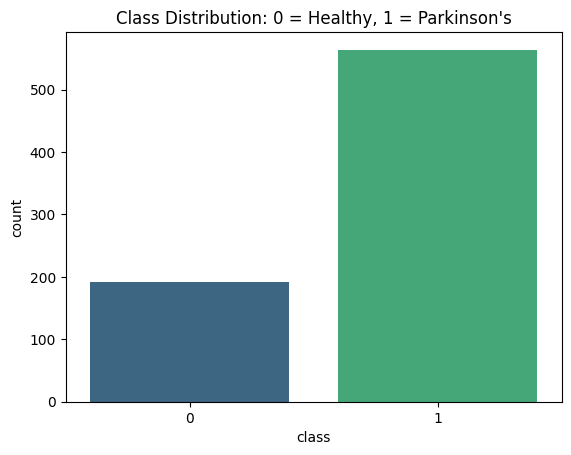

In [ ]:
# Visualize initial class distribution
sns.countplot(x='class', hue='class', data=df, palette='viridis', legend=False)
plt.title("Class Distribution: 0 = Healthy, 1 = Parkinson's")
plt.show()

4. Feature Preparation & Scaling

In [ ]:
# Split features and target
X = df.drop('class', axis=1)
y = df['class']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

5. Address Class Imbalance with SMOTE

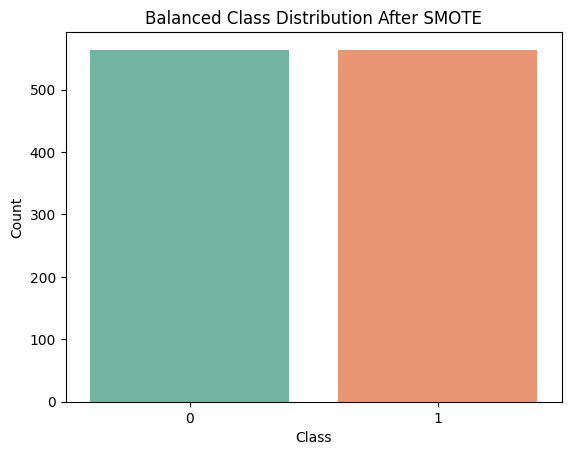

In [ ]:
# Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_scaled, y)

# Visualize balanced class distribution
sns.countplot(x=y_resampled, hue=y_resampled, palette='Set2', legend=False)
plt.title("Balanced Class Distribution After SMOTE")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

6. Train-Test Split and Final Scaling

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

7. Train and Optimize SVM with GridSearchCV

In [ ]:
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto'],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(), param_grid, refit=True, cv=5)
grid.fit(X_train_scaled, y_train)

print("Best Parameters Found:", grid.best_params_)

Best Parameters Found: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}


8. Evaluate the Model

In [ ]:
y_pred = grid.predict(X_test_scaled)

print("✅ Accuracy:", accuracy_score(y_test, y_pred))
print("✅ Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("✅ Classification Report:\n", classification_report(y_test, y_pred))

✅ Accuracy: 0.9734513274336283
✅ Confusion Matrix:
 [[107   2]
 [  4 113]]
✅ Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.98      0.97       109
           1       0.98      0.97      0.97       117

    accuracy                           0.97       226
   macro avg       0.97      0.97      0.97       226
weighted avg       0.97      0.97      0.97       226



9. Feature Importance with Mutual Information

In [ ]:
selector = SelectKBest(score_func=mutual_info_classif, k=10)
selector.fit(X_train_scaled, y_train)

top_indices = selector.get_support(indices=True)
top_features = X.columns[top_indices]
top_scores = selector.scores_[top_indices]

10. Plot Top 10 Important Features

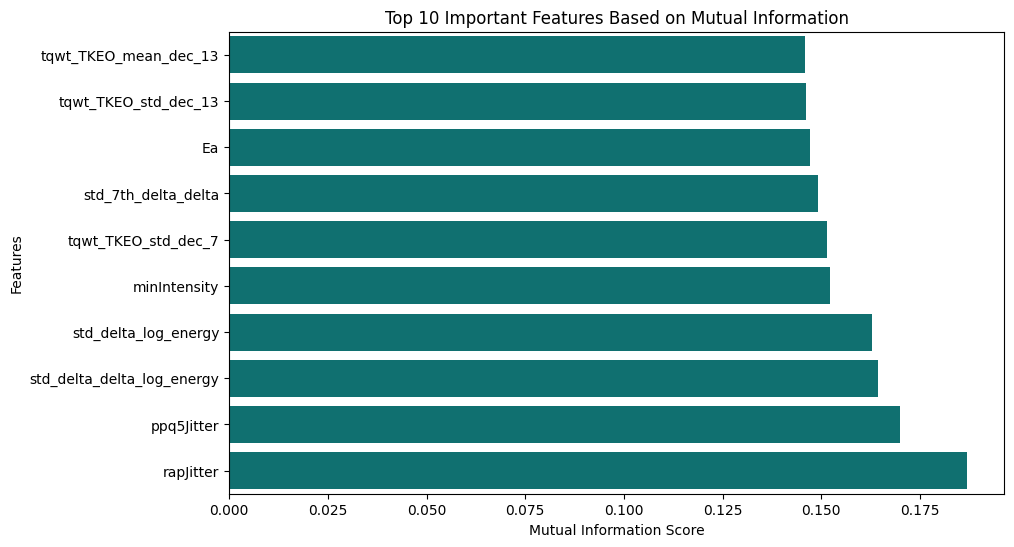

In [ ]:
# Bar Plot
feature_importance_df = pd.DataFrame({'Feature': top_features, 'Importance Score': top_scores})
feature_importance_df = feature_importance_df.sort_values(by='Importance Score', ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance Score', y='Feature', data=feature_importance_df, color='teal')
plt.title('Top 10 Important Features Based on Mutual Information')
plt.xlabel('Mutual Information Score')
plt.ylabel('Features')
plt.show()

11. Correlation Matrix for Top Features

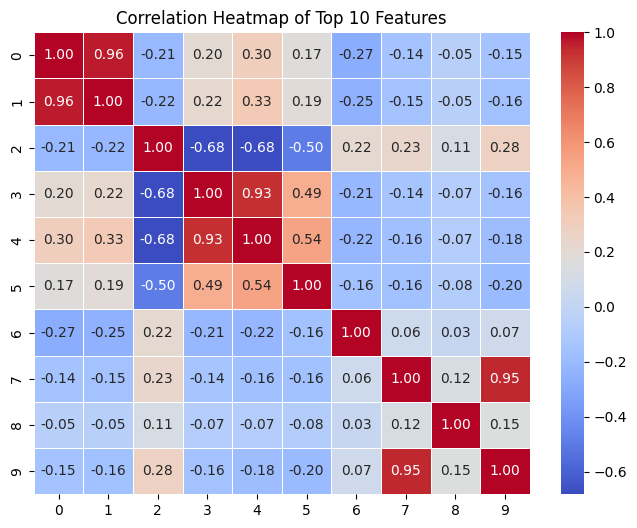

In [ ]:
top_feature_data = X_train_scaled[:, top_indices]
corr_matrix = pd.DataFrame(top_feature_data).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', cbar=True, fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Top 10 Features')
plt.show()

12. Cumulative Feature Importance Plot

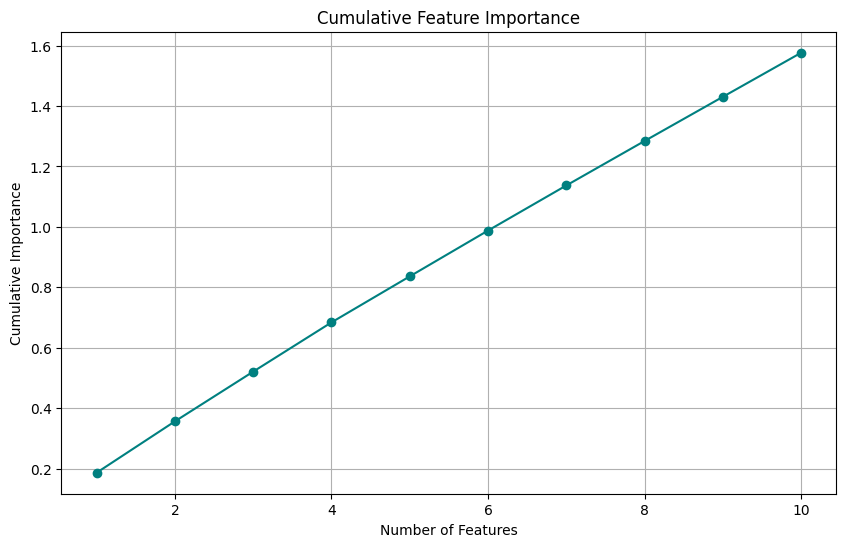

In [ ]:
sorted_scores = np.sort(top_scores)[::-1]
cumulative_importance = np.cumsum(sorted_scores)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(sorted_scores)+1), cumulative_importance, marker='o', color='teal')
plt.title('Cumulative Feature Importance')
plt.xlabel('Number of Features')
plt.ylabel('Cumulative Importance')
plt.grid(True)
plt.show()